In [115]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
import sklearn

In [117]:
data1= pd.read_csv('Iris.csv')

In [119]:
data1.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [121]:
data1.shape

(150, 6)

In [123]:
data1.columns

Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')

In [125]:
y= data1['Species']

In [127]:
y.head()

0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: Species, dtype: object

In [129]:
x= data1.drop(['Species', 'Id'], axis=1)

In [131]:
x.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [133]:
print("Shape of X:", x.shape)
print("Shape of y:", y.shape)

Shape of X: (150, 4)
Shape of y: (150,)


In [135]:
from sklearn.preprocessing import LabelEncoder

In [137]:
LE= LabelEncoder()
y= LE.fit_transform(y)

In [139]:
print(LE.classes_)

['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


In [141]:
print("Target shape:", y.shape)
print("Unique labels:", set(y))

Target shape: (150,)
Unique labels: {0, 1, 2}


In [143]:
from sklearn.model_selection import train_test_split

In [145]:
x_train, x_test, y_train, y_test= train_test_split(x, y, test_size= 0.2, random_state= 42, stratify=y)

In [147]:
print("X_train shape:", x_train.shape)
print("X_test shape:", x_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (120, 4)
X_test shape: (30, 4)
y_train shape: (120,)
y_test shape: (30,)


In [149]:
from sklearn.preprocessing import StandardScaler

In [151]:
scaler= StandardScaler()
X_train= scaler.fit_transform(x_train)    # Fit on training data and scale it
X_test= scaler.transform(x_test)          # Scale test data using the same scaler

In [157]:
print(X_train[:5])

[[-1.72156775 -0.32483982 -1.34703555 -1.32016847]
 [-1.12449223 -1.22612948  0.41429037  0.65186742]
 [ 1.14439475 -0.55016223  0.58474127  0.25746024]
 [-1.12449223  0.12580502 -1.29021859 -1.45163753]
 [-0.40800161 -1.22612948  0.13020555  0.12599118]]


In [159]:
print("Training means:", x_train.mean(axis=0))
print("Training standard deviations:", X_train.std(axis=0))

Training means: SepalLengthCm    5.841667
SepalWidthCm     3.044167
PetalLengthCm    3.770833
PetalWidthCm     1.204167
dtype: float64
Training standard deviations: [1. 1. 1. 1.]


In [161]:
print(X_train.shape)
print(X_test.shape)
print(X_train[:5])

(120, 4)
(30, 4)
[[-1.72156775 -0.32483982 -1.34703555 -1.32016847]
 [-1.12449223 -1.22612948  0.41429037  0.65186742]
 [ 1.14439475 -0.55016223  0.58474127  0.25746024]
 [-1.12449223  0.12580502 -1.29021859 -1.45163753]
 [-0.40800161 -1.22612948  0.13020555  0.12599118]]


In [163]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [165]:
model = Sequential([                                   # Creates an ANN model with layers arranged sequentially
    Dense(8, activation='relu', input_shape=(4,)),     # Creates the first hidden layer with 8 neurons and 4 input features
    Dense(4, activation='relu'),                       # Creates the second hidden layer with 4 neurons and ReLU activation
    Dense(3, activation='softmax')                     # Creates the output layer with 3 neurons for the 3 flower classes
])

C:\Users\angel\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [167]:
model.summary()            # Displays the model architecture, output shapes, and parameter counts

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                      │ (None, 8)                   │              40 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 4)                   │              36 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 3)                   │              15 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 91 (364.00 B)

 Trainable params: 91 (364.00 B)

 Non-trainable params: 0 (0.00 B)

In [169]:
model.compile(                                # Configures the model for training
    optimizer='adam',                          # Uses the Adam optimizer to update weights and biases during learning
    loss='sparse_categorical_crossentropy',     # Measures prediction error for multiclass classification with integer labels
    metrics=['accuracy']                          # Tracks the proportion of correctly classified samples
)                                           # Completes the model compilation

In [173]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=8,
    validation_split=0.2
)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.6146 - loss: 0.6896 - val_accuracy: 0.7500 - val_loss: 0.6265
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6562 - loss: 0.6400 - val_accuracy: 0.7500 - val_loss: 0.6059
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7604 - loss: 0.6163 - val_accuracy: 0.7500 - val_loss: 0.5930
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7812 - loss: 0.5969 - val_accuracy: 0.7500 - val_loss: 0.5857
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7812 - loss: 0.5815 - val_accuracy: 0.7083 - val_loss: 0.5789
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8021 - loss: 0.5693 - val_accuracy: 0.7083 - val_loss: 0.5716
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8229 - loss: 0.5591 - val_accuracy: 0.7083 - val_loss: 0.5631
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8542 - loss: 0.5497 - val_accuracy: 0.

In [175]:
print(history.history.keys())  # Displays the training and validation metrics recorded for each epoch

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


In [177]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)  # Evaluates the trained ANN on unseen test data

print("Test Loss:", test_loss)  # Displays the model's loss on the test dataset
print("Test Accuracy:", test_accuracy)  # Displays the model's accuracy on the test dataset

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 321ms/step - accuracy: 0.9333 - loss: 0.2390
Test Loss: 0.2389831393957138
Test Accuracy: 0.9333333373069763


In [179]:
print("Final Training Accuracy:", history.history['accuracy'][-1])  # Displays the training accuracy from the final epoch

print("Final Training Loss:", history.history['loss'][-1])  # Displays the training loss from the final epoch

print("Final Validation Accuracy:", history.history['val_accuracy'][-1])  # Displays the validation accuracy from the final epoch

print("Final Validation Loss:", history.history['val_loss'][-1])  # Displays the validation loss from the final epoch

Final Training Accuracy: 0.9479166865348816
Final Training Loss: 0.2182580679655075
Final Validation Accuracy: 1.0
Final Validation Loss: 0.14954383671283722


In [181]:
predictions = model.predict(X_test)  # Predicts the class probabilities for all test flowers

print(predictions[0])  # Displays the predicted probabilities for the first test flower

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step
[9.9992788e-01 7.1984323e-05 1.5551826e-07]


In [185]:
import numpy as np  # Imports NumPy for numerical operations

predicted_class = np.argmax(predictions[0])  # Finds the index of the highest probability

print("Predicted class:", predicted_class)  # Displays the predicted class label

Predicted class: 0


In [189]:
predicted_class = np.argmax(predictions[0])  # Finds the index of the highest predicted probability

predicted_species = LE.inverse_transform([predicted_class])  # Converts the encoded class back into its original species name

print("Predicted Flower Species:", predicted_species[0])  # Displays the predicted flower specie

Predicted Flower Species: Iris-setosa


In [193]:
actual_species = LE.inverse_transform([y_test[0]])[0]  # Converts the first test flower's actual label into its species name

print("Actual Species:", actual_species)  # Displays the actual species
print("Predicted Species:", predicted_species[0])  # Displays the predicted species

Actual Species: Iris-setosa
Predicted Species: Iris-setosa


In [195]:
import numpy as np
from sklearn.metrics import confusion_matrix

# Predict probabilities for all test samples
predictions = model.predict(X_test)

# Convert probabilities into predicted class labels
y_pred = np.argmax(predictions, axis=1)

# Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

print(cm)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


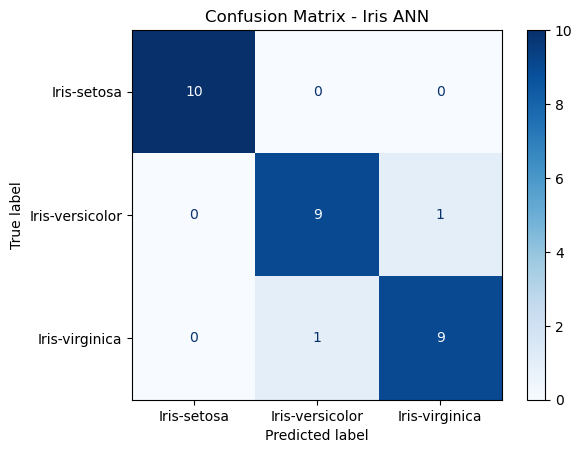

In [199]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=LE.classes_
)

disp.plot(cmap='Blues')
plt.title("Confusion Matrix - Iris ANN")
plt.show()

In [201]:
from sklearn.metrics import classification_report

# Generate predictions
y_pred = np.argmax(model.predict(X_test), axis=1)

# Print classification report
print(classification_report(y_test, y_pred, target_names=LE.classes_))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30

